# Image Processing Lab — Four Tasks

**Python · OpenCV · NumPy · Google Colab / VS Code**

## Setup

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Works in Google Colab and in a local VS Code Jupyter notebook.
def upload_image():
    try:
        from google.colab import files
    except ImportError:
        # Local Windows: pick a JPG/PNG with the normal file dialog.
        from tkinter import Tk, filedialog
        root = Tk()
        root.withdraw()
        root.attributes('-topmost', True)
        filename = filedialog.askopenfilename(
            title="Choose an image",
            filetypes=[("Image files", "*.png *.jpg *.jpeg"), ("All files", "*.*")],
        )
        root.destroy()
        if not filename:
            raise ValueError("No image selected.")
        data = np.fromfile(filename, dtype=np.uint8)
    else:
        uploaded = files.upload()
        if not uploaded:
            raise ValueError("No image uploaded.")
        data = np.frombuffer(next(iter(uploaded.values())), dtype=np.uint8)

    image = cv2.imdecode(data, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Please select a valid JPG or PNG image.")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def show(*items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 4))
    for ax, (title, image) in zip(np.atleast_1d(axes), items):
        ax.imshow(image, cmap='gray' if image.ndim == 2 else None, vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print("Setup is ready")

# Task 1 — RGB Channels and Grayscale

## 1.1 RGB Channel Separation

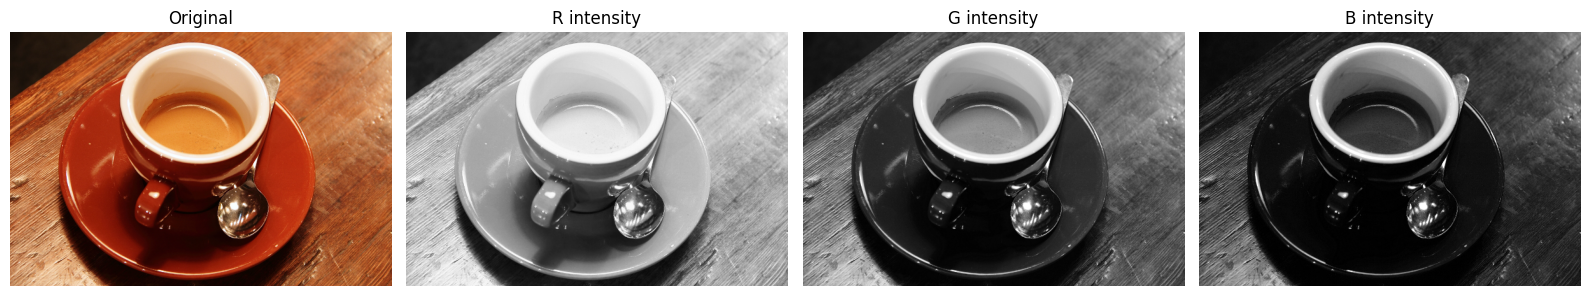

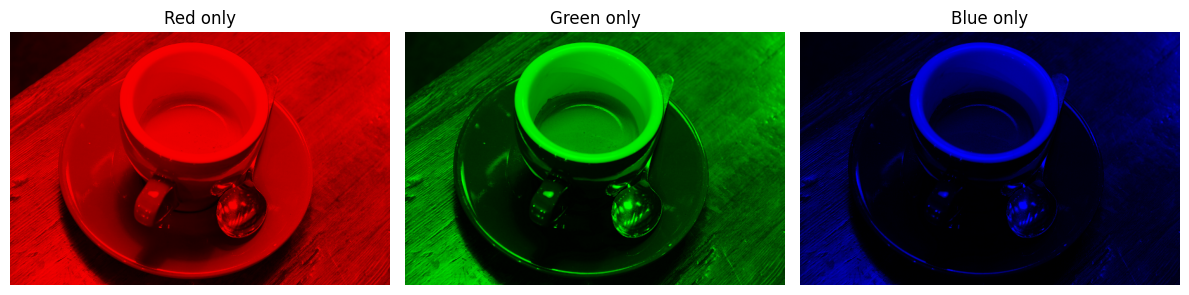

In [2]:
img = upload_image()  # Upload a color image

R, G, B = cv2.split(img)
show(("Original", img), ("R intensity", R), ("G intensity", G), ("B intensity", B))

red = np.zeros_like(img)
green = np.zeros_like(img)
blue = np.zeros_like(img)
red[:, :, 0] = R
green[:, :, 1] = G
blue[:, :, 2] = B
show(("Red only", red), ("Green only", green), ("Blue only", blue))

## 1.2 Custom Grayscale Conversion

`Gray = 0.299R + 0.587G + 0.114B`

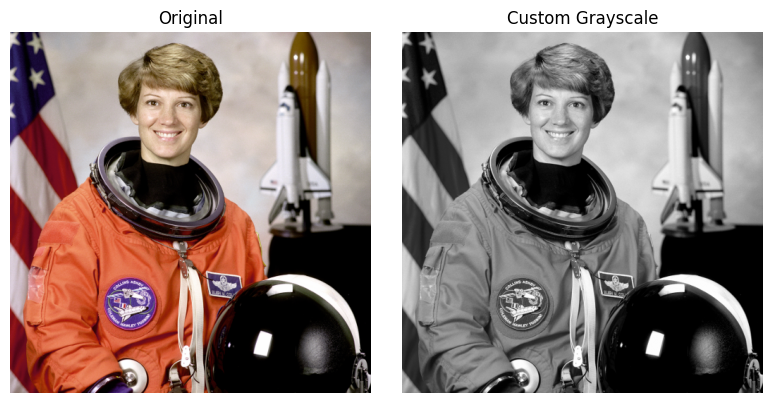

In [3]:
img = upload_image()  # Upload a color image
R, G, B = cv2.split(img)

gray = (0.299 * R + 0.587 * G + 0.114 * B).astype(np.uint8)
show(("Original", img), ("Custom Grayscale", gray))

# Task 2 — Point Operations and Color Channels

## 2.1 Arithmetic Operations

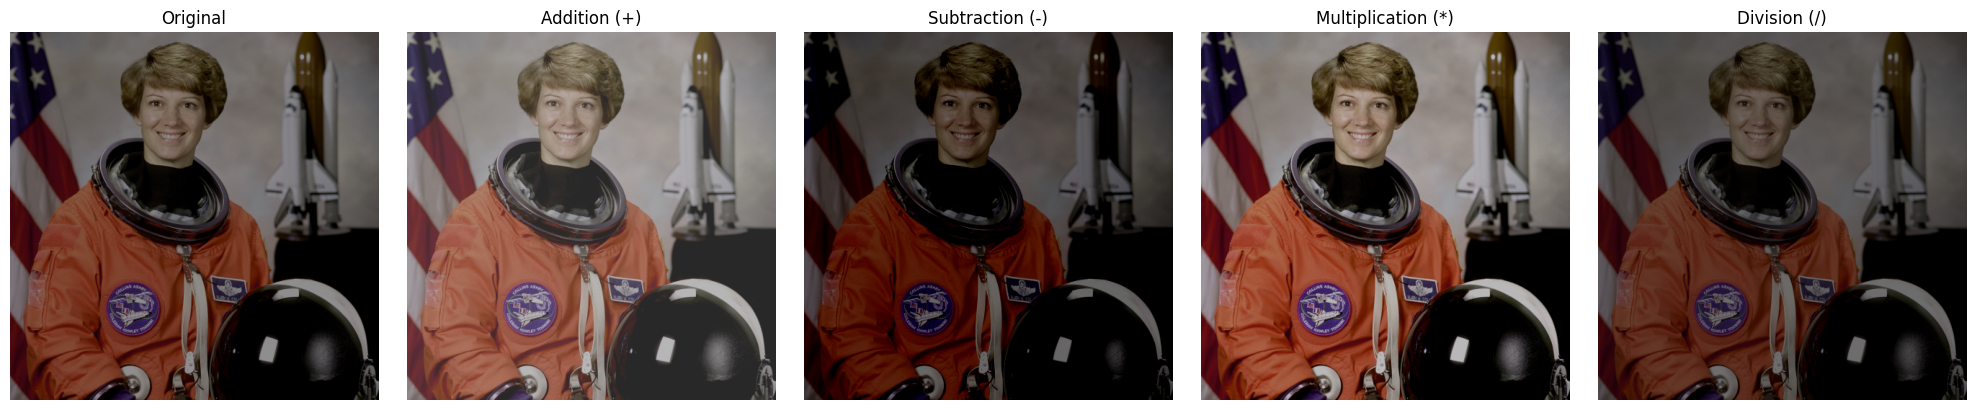

Selected operation: Multiplication (*) | Factor: 1.3


In [4]:
img = upload_image()  # Upload a dark image

amount = 40
factor = 1.3

# Arithmetic operations
addition = cv2.add(img, np.full_like(img, amount))
subtraction = cv2.subtract(img, np.full_like(img, amount))
multiplication = np.clip(img.astype(float) * factor, 0, 255).astype(np.uint8)
division = np.clip(img.astype(float) / factor, 0, 255).astype(np.uint8)

# Display all results
show(
    ("Original", img),
    ("Addition (+)", addition),
    ("Subtraction (-)", subtraction),
    ("Multiplication (*)", multiplication),
    ("Division (/)", division)
)

print("Selected operation: Multiplication (*) | Factor:", factor)


## 2.2 Complementary and Solarization

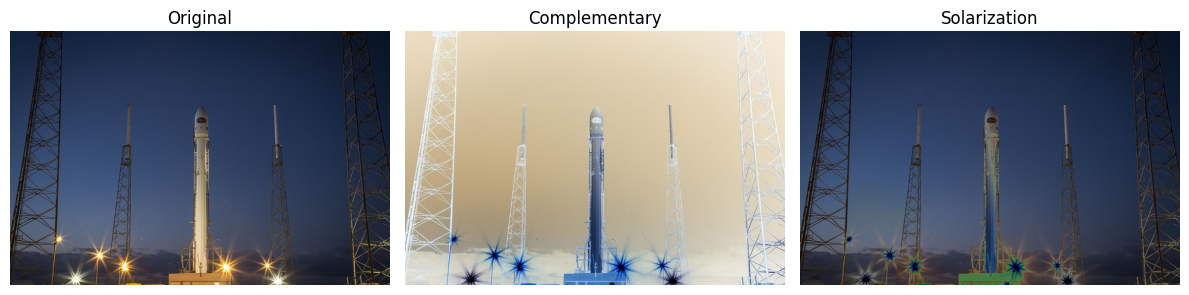

Solarization threshold: 128


In [5]:
img = upload_image()  # Upload an image with bright areas
threshold = 128

# Complementary (negative)
negative = 255 - img

# Solarization
solar = np.where(img > threshold, 255 - img, img).astype(np.uint8)

# Display both effects
show(("Original", img), ("Complementary", negative), ("Solarization", solar))
print("Solarization threshold:", threshold)


## 2.3 Channel Elimination

Mean R, G, B: [158.5690875  85.794025  204.8408375]
First 3x3 RGB pixels: [[[ 21  13 195]
  [ 21  13 195]
  [ 20  11 195]]

 [[ 21  13 195]
  [ 21  13 195]
  [ 20  14 195]]

 [[ 21  14 195]
  [ 23  13 196]
  [ 20  14 195]]]


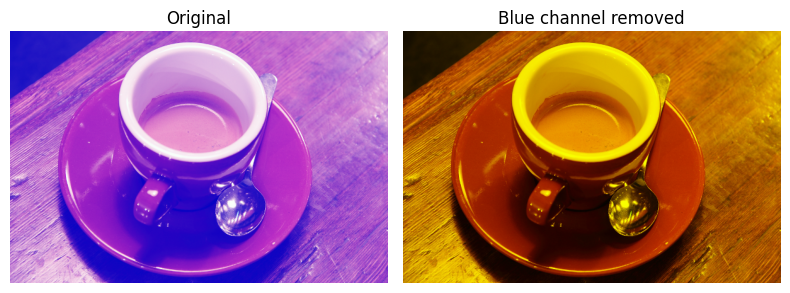

In [6]:
img = upload_image()  # Upload an image with a blue color cast

print('Mean R, G, B:', img.mean(axis=(0, 1)))
print('First 3x3 RGB pixels:', img[:3, :3, :])

fixed = img.copy()
fixed[:, :, 2] = 0  # R=0, G=1, B=2  -> eliminate Blue

show(("Original", img), ("Blue channel removed", fixed))

# Task 3 — Histogram Enhancement

## 3.1 Histogram Stretching and Equalization

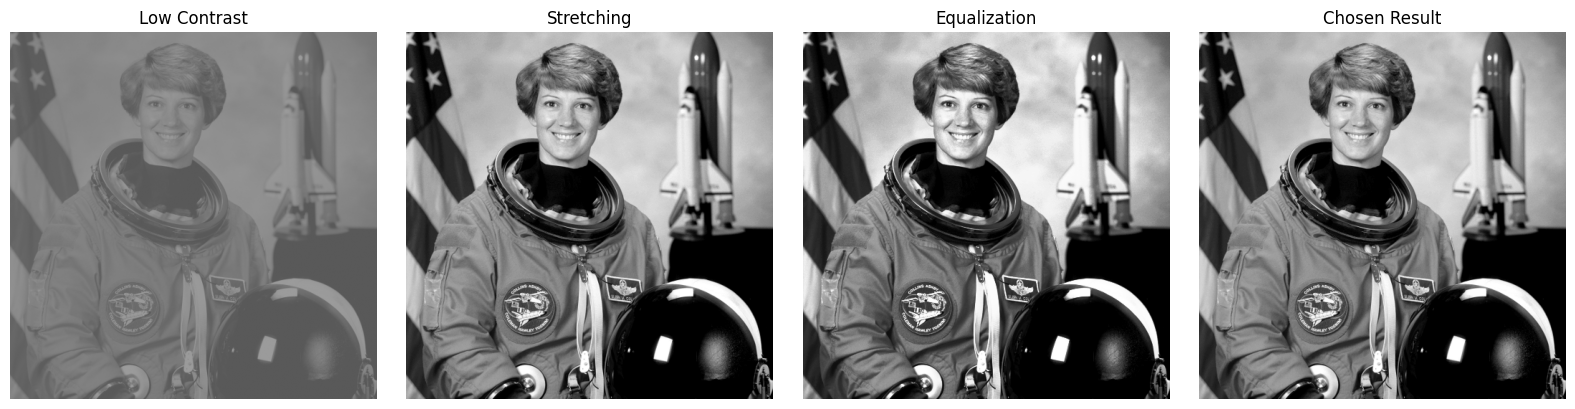

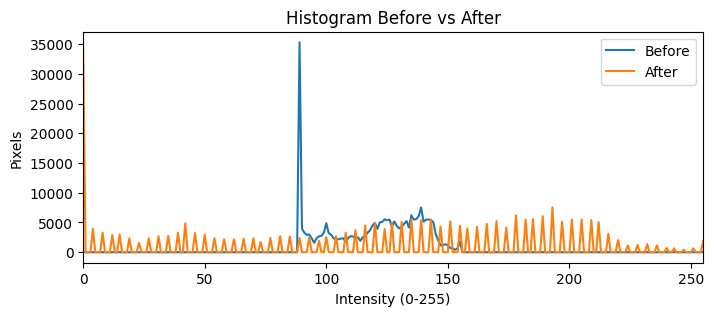

Chosen method: stretch | Extra brightness: 0


In [7]:
img = upload_image()  # Upload a low-contrast image
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
stretch = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
equalized = cv2.equalizeHist(gray)

method = 'stretch'  # Choose 'stretch' or 'equalize'
result = stretch if method == 'stretch' else equalized

brightness = 0  # Adjust only if needed
result = cv2.add(result, np.full_like(result, brightness))

show(("Low Contrast", gray), ("Stretching", stretch),
     ("Equalization", equalized), ("Chosen Result", result))

plt.figure(figsize=(8, 3))
plt.plot(hist, label='Before')
plt.plot(cv2.calcHist([result], [0], None, [256], [0, 256]), label='After')
plt.xlim(0, 255)
plt.title('Histogram Before vs After')
plt.xlabel('Intensity (0-255)')
plt.ylabel('Pixels')
plt.legend()
plt.show()
print('Chosen method:', method, '| Extra brightness:', brightness)

# Task 4 — Filtering and Edge Detection

## 4.1 Salt-and-Pepper Noise, Median Filter, and SNR

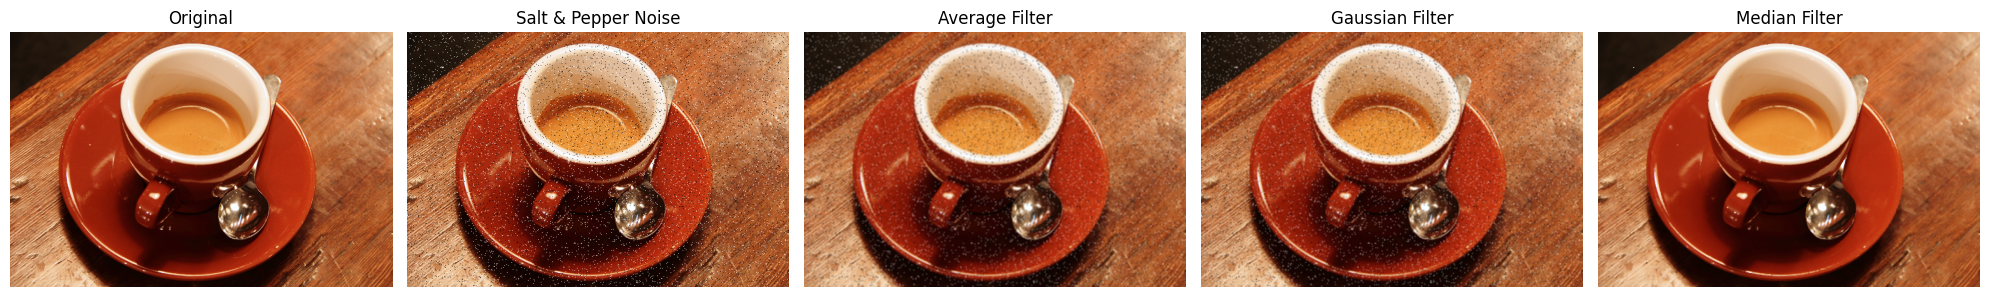

SNR before filtering   : 11.36 dB
SNR after Average      : 18.34 dB
SNR after Gaussian     : 18.2 dB
SNR after Median       : 23.24 dB


In [8]:
img = upload_image()  # Upload a clean image
np.random.seed(7)  # Reproducible noise

# Add Salt & Pepper noise
noisy = img.copy()
random_pixels = np.random.rand(*img.shape[:2])
noisy[random_pixels < 0.025] = 0
noisy[random_pixels > 0.975] = 255

# Apply different smoothing filters
average_filtered = cv2.blur(noisy, (3, 3))
gaussian_filtered = cv2.GaussianBlur(noisy, (3, 3), 0)
median_filtered = cv2.medianBlur(noisy, 3)

# SNR function
def snr(original, changed):
    a = original.astype(float)
    b = changed.astype(float)
    signal_power = np.sum(a ** 2)
    error_power = np.sum((a - b) ** 2)
    return float('inf') if error_power == 0 else 10 * np.log10(signal_power / error_power)

# Show all cases
show(
    ("Original", img),
    ("Salt & Pepper Noise", noisy),
    ("Average Filter", average_filtered),
    ("Gaussian Filter", gaussian_filtered),
    ("Median Filter", median_filtered)
)

# Print SNR values
print('SNR before filtering   :', round(snr(img, noisy), 2), 'dB')
print('SNR after Average      :', round(snr(img, average_filtered), 2), 'dB')
print('SNR after Gaussian     :', round(snr(img, gaussian_filtered), 2), 'dB')
print('SNR after Median       :', round(snr(img, median_filtered), 2), 'dB')

## 4.2 Gaussian Blur and Sharpening

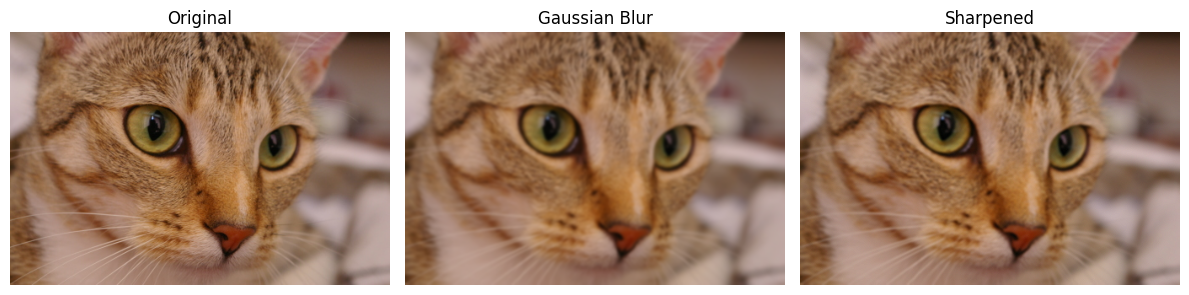

In [9]:
img = upload_image()  # Upload a clear image with details
blurred = cv2.GaussianBlur(img, (7, 7), 0)

kernel = np.array([[0, -1, 0],
                   [-1, 5, -1],
                   [0, -1, 0]])
sharpened = cv2.filter2D(blurred, -1, kernel)

show(("Original", img), ("Gaussian Blur", blurred), ("Sharpened", sharpened))

## 4.3 Canny Edge Detection

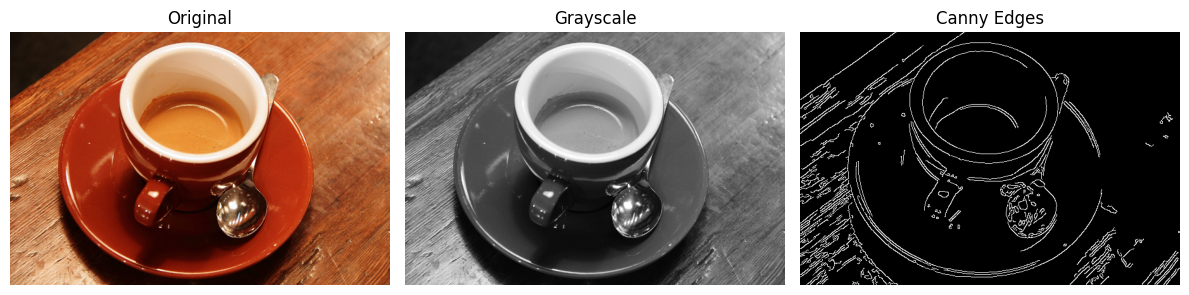

In [10]:
img = upload_image()  # Upload an image with distinct edges
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blurred, 50, 150)

show(("Original", img), ("Grayscale", gray), ("Canny Edges", edges))